## Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Custom functions
from Functions_carbon_18sep2026_3 import prediction

## Paths

In [3]:
light_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Doortje\Data\light_1805_1711.txt"
temp_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Doortje\Data\temp_1805_1711.txt"
wind_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Doortje\Data\wind_1805_1711.txt"

conc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_modeling\Data\AVP2016_concentrations_data.xlsx"
lake_data_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\Verspagen_AmstelveensePoel.xlsx"
DO_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\DO_patterns.xlsx"

light_data = np.loadtxt(light_path)
temp_data = np.loadtxt(temp_path)
wind_data = np.loadtxt(wind_path)

conc_data = pd.read_excel(conc_path)
lake_data = pd.read_excel(lake_data_path, sheet_name="water_parameters")
lake_data2 = pd.read_excel(lake_data_path, sheet_name="HF_WQ")
DO_data = pd.read_excel(DO_path)

In [4]:
conc_data = conc_data[:][0:-3] # Remove NaN rows
lake_data['date'] = pd.to_datetime(                   # Create a column for proper datetime format
    lake_data['year_yyyy'].astype(str) + '-' +
    lake_data['month_mm'].astype(str).str.zfill(2) + '-' +
    lake_data['day_of_month_dd'].astype(str).str.zfill(2) + ' ' +
    lake_data['time_hms'].astype(str),
    format='%Y-%m-%d %H:%M:%S'
)

lake_data2["date"] = pd.to_datetime(
    lake_data2["date_time_ymd_hms"]
)

In [6]:
### OUTPUT ###

output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"
file_name = "chemcalc_8okt2026"

## Parameters

In [8]:
# time
tst = 60                # Time step in seconds
params = {}  # Initialize parameter dictionary

# General parameters
params["R"] = 8.3144621  # universal gas constant in J/mol K (Jahne et al., 1987)
params["Ea"] = 19.51E3   # activation energy (Jahne et al., 1987), converted from kJ to J
params["A"] = 5.019E-6 * (60 * 60) # scaling constant (Jahne et al., 1987), A is converted from cm2/s to m2/h

# Lake
params["D"] = 0.0027 / 24    # Dilution rate      
params["K_bg"] = 1.3858   # background turbidity in m-1
params["z_max"] = 1.8     # Depth in m  
params['sal'] = 0.521     # salinity in g/L      
# params["CO2_min"] = 3.03982E-06;  # CO2 input from mineralization in mol C/L/h
params["CO2_min"] =0

# phytoplankton
params["N_Chl"] = 6.764E-7   # mol N / ug Chl a
params["P_Chl"] = 1.91E-8    # mol P / ug Chl a
params["S_Chl"] = 1.91E-8    # mol S / ug Chl a
params["C_Chl"] = 4.6E-6     # mol C / ug Chl a

params["PON_POC"] = 0.1405044                       # PON/POC ratio, from carbon_ratios.ipynb
params["POP_POC"] = 0.0038505                       # POP/POC ratio, from carbon_ratios.ipynb
params["S_C"] = params["S_Chl"] / params["C_Chl"]   # S/C ratio

# params["h_i"] = 40     # half saturation constant for light in micromol photons/m2/s
# params["h_i"] = 55.42615437453733
params["h_i"] = 27.602520619602675
# params["h_i"] = 53.95886329834006
params["k"] = 0.0222 / params["C_Chl"]  # specific light attenuation (m2/ mol C)
# params["m"] = 0.1/24   # mortality rate in h-1 
# params["m"] = 0.005009804936307886
params["m"] = 0.0051380757673641295 * 0.5
# params["m"] = 0.008348931948542176

params["mu_max_cons"] = 3.46E-2           # constant used to determine max growth rate in h-1
params["Q_ten"] = 2.63                    # Change in growth rate for a 10C temperature increase
# params["r_max"] = 2.89E-8                 # maximum respiration rate         
# params["r_max"] = 2.89e-09 / params["C_Chl"]
params["r_max"] = 0.0006282608695652174
# params["r_max"] = 0.03655225464011498
# params["v_c_max"] = 7.2E-7                # Maximum carbon uptake in mol C/μg Chl a/h
# params["v_c_max"] = 4.463395875475215e-06 / params["C_Chl"]
params["v_c_max"] = 0.6118895625066884
# params["v_c_max"] = 0.7745801259632489

# params["k_f"] = 8.0E4 / 24   # Converted to L (M m2 h)-1
# params["k_f"] = 3.33333333
# params["k_f"] = 4553.547849285905
# params["cp"] = 0.5
# params['cf'] = 1.99313124328e5    # calcification factor
# params['cf'] = 1277643.164689641
params['cf'] = 1898469.4869896546 * 0.0003

params["f_c"] = 0.4          # fraction of maximum C-uptake made up by CO2 uptake
params["h_co2"] = 7.1E-7     # half saturation constant for CO2 [mol/L] (Ji et al, 2020)      
params["h_hco3"] = 8.5E-6    # half saturation constant for HCO3 [mol/L] (Ji et al, 2020)   

# Initialize nutrients and carbon chemistry
params["N_in"]   = 0.2E-3		# initial nitrogen concentration, mol/L
params["P_t_in"] = 5.0E-6       # intial phosphorus concentration, mol/L
params["S_in"]   = 2.0E-5       # Initial sulfur concentration, mol/L
params["Ca_in"]  = 1617.495346E-6 # initial calcium concentration, mol/L

# B = 12.854 * params["C_Chl"]	    # Initial  biomass (mol C/L)
B = 635.2652778 / (10**6)

params["Alk_in"] = 3.06E-3  # Initial Alkalinity in Eq/L

ppm_CO2 = 400   # pCO2 atmosphere in ppm
params['atm_CO2'] = ppm_CO2 * 1E-6   # pCO2 atmosphere in atm
pH = 8.83                  # Initial pH
params['H_in'] = 10**(-pH)              # Initial hydrogen conc [mol/L or M]
params["DIC_in"] = 3.507E-3             # initial DIC [mol C/L]

oldst = [params['DIC_in'], params['Alk_in'], params["N_in"], params["P_t_in"], params["S_in"], B, params["Ca_in"]]

## Main

In [14]:
# Initialize column names for the output dataframe
name_list = ["B", "d_B",
             "CO2", "HCO3", "CO3", "Ca",
             "DIC", "pH", "Alk", "Alk_dil",
             "N", "P_t", "S",
             "I_in", "I_out", "f_i",
             "t_c",
             "mu", "mu_max", "v_c", "v_co2",
             "CO2_atm", "CO2_min", "DIC_dil",
             "calcification", "IAP", "K_sp"
            ]

df = prediction(temp_data, light_data, wind_data, params, oldst, tst, name_list)

In [15]:
df['date'] = pd.date_range(start="2016-05-18", periods=len(df), freq="h")

In [16]:
### SAVING ###
out = os.path.join(output_dir, f"Dataframes\\{file_name}.xlsx")
df.to_excel(out)

## Plot

### Main plot

In [14]:
### Prep ##
# df['date'] = pd.date_range(start="2016-05-18", periods=len(df), freq="h")

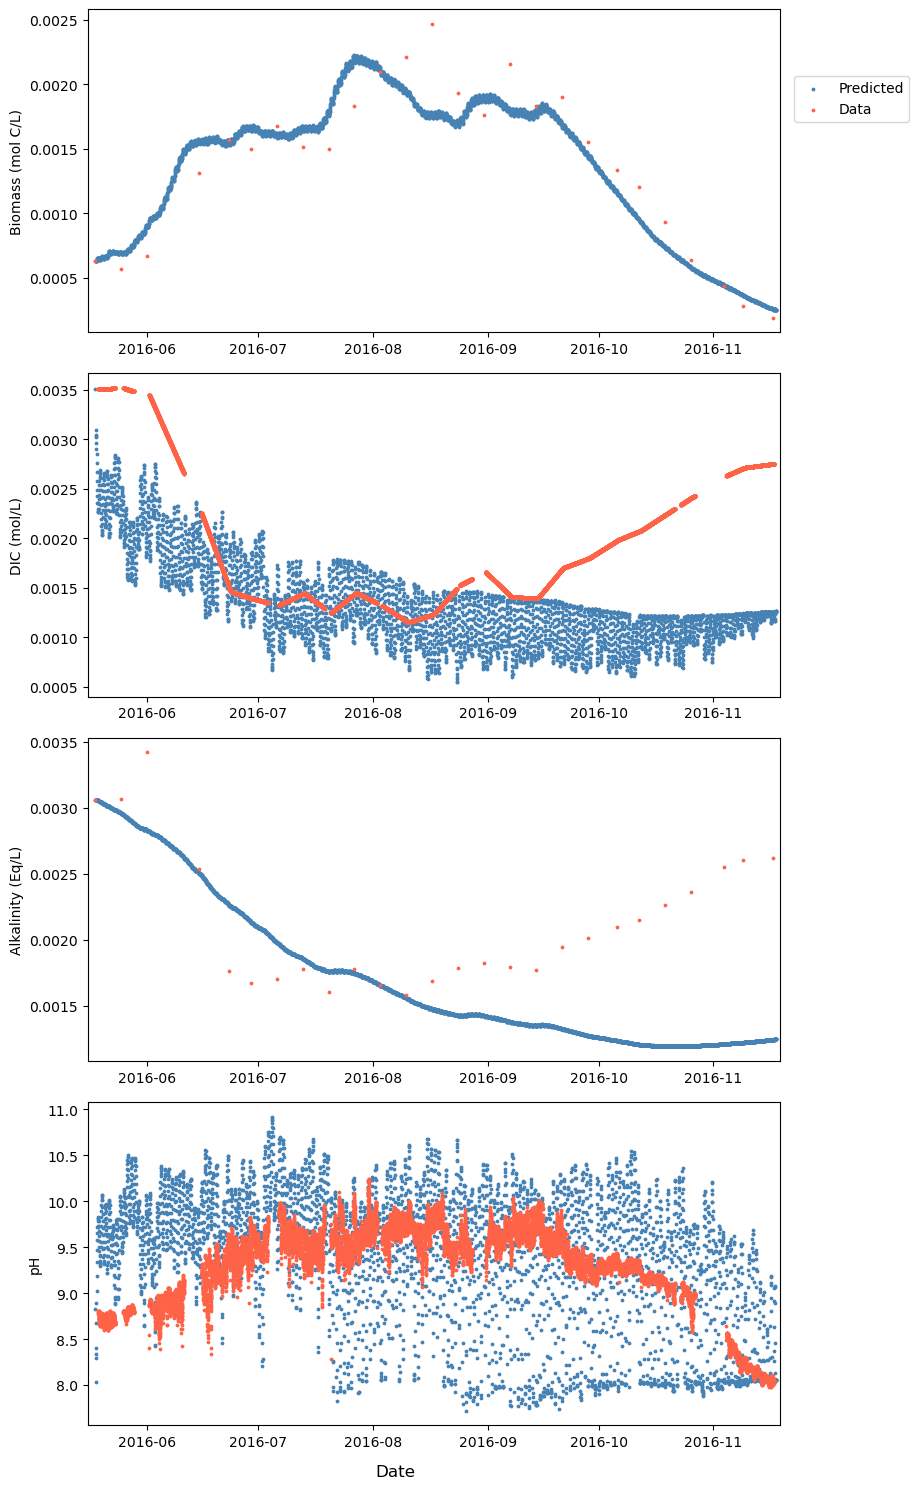

In [15]:
fig, axs = plt.subplots(4, figsize=(8, 15))

######## Biomass ########
axs[0].scatter(df["date"], df["B"], s=3, color="steelblue", label="Predicted Biomass")
axs[0].scatter(conc_data["date"], conc_data["POC"]/ (10**6), s=3, color="tomato", label="chla from Data")

######## DIC ########
axs[1].scatter(df["date"], df['DIC'], s=3, color="steelblue", label="Predicted DIC")
# axs[1].scatter(conc_data['date'], conc_data['DIC']*(10**-6), s=3, color="tomato", label="DIC from Data")
axs[1].scatter(lake_data2['date'], lake_data2['DIC_umolL']*(10**-6), s=3, color="tomato", label="DIC from Data")

######## Alkalinity ########
axs[2].scatter(df["date"], df['Alk'], s=3, color="steelblue", label="Predicted ALkalinity")
axs[2].scatter(conc_data['date'], conc_data['Alk']*(10**-6), s=3, color="tomato", label="ALkalinity from Data")

######## pH ########
axs[3].scatter(df["date"], df['pH'], s=3, color="steelblue", label="Predicted pH")
# axs[3].scatter(conc_data['date'], conc_data['pH'], s=3, color="tomato", label="pH from Data")
# axs[3].scatter(lake_data['date'], lake_data['pH'], s=3, color="tomato", label="pH from Data")
axs[3].scatter(lake_data2['date'], lake_data2['sensor_pH'], s=3, color="tomato", label="pH from Data")


######## CO2 mineralization ########
# axs[4].scatter(df["date"], df['CO2_min']+params['r_max'], s=3, color="steelblue", label="Predicted CO2_min")
# axs[4].scatter(DO_data['date_time_ymd_hms'][DO_data['DO_POC_h']<0], -DO_data['DO_POC_h'][DO_data['DO_POC_h']<0], s=3, color="tomato", label="r_c from Data")
# axs[4].set_ylim(0, 0.25)

######## v_c & u_c ########
# axs[5].scatter(df["date"], df['v_c'], s=3, color="steelblue", label="Predicted v_c")
# axs[5].scatter(DO_data['date_time_ymd_hms'][DO_data['DO_POC_h']>0], DO_data['DO_POC_h'][DO_data['DO_POC_h']>0], s=3, color="tomato", label="v_c from Data")

# axs[6].scatter(df["date"], df['u_c'], s=3, color="steelblue", label="Predicted v_c")
# axs[6].scatter(DO_data['date_time_ymd_hms'][DO_data['DO_POC_h']>0], DO_data['DO_POC_h'][DO_data['DO_POC_h']>0], s=3, color="tomato", label="v_c from Data")

######## Temperature ########
# axs[7].scatter(df["date"], df['t_c'], s=3, color="tomato")

### Labels ###
axs[0].set_ylabel('Biomass (mol C/L)')
axs[1].set_ylabel('DIC (mol/L)')
axs[2].set_ylabel('Alkalinity (Eq/L)')
axs[3].set_ylabel('pH')
# axs[4].set_ylabel('CO2 min + r (mol/L/h)')
# axs[5].set_ylabel('v_c (mol C/mol POC/h)')
# axs[6].set_ylabel('u_c (mol C/mol POC/h')
# axs[7].set_ylabel('Temperature (\u00b0 C)')

for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))
    # ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-05-20"))
    
fig.legend(['Predicted','Data'], loc="upper left", bbox_to_anchor=(0.99, 0.95))
fig.supxlabel('Date')
plt.tight_layout()

##### Saving #####
out = os.path.join(output_dir, f"Plots\\{file_name}_data_comparisons.png")
plt.savefig(out)

### Partial plots

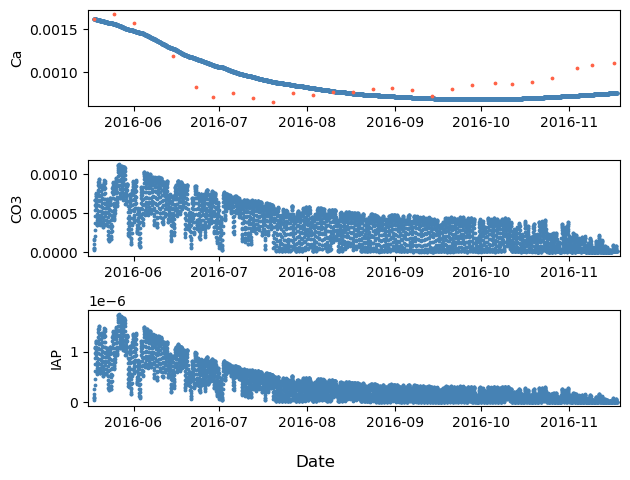

In [32]:
fig, axs = plt.subplots(3)

axs[0].scatter(df["date"], df["Ca"], s=3, color="steelblue")
axs[0].scatter(conc_data["date"], conc_data["Ca"]/ (10**6), s=3, color="tomato")
axs[0].set_ylabel('Ca')

axs[1].scatter(df["date"], df["CO3"], s=3, color="steelblue")
axs[1].set_ylabel('CO3')

axs[2].scatter(df["date"], df["IAP"], s=3, color="steelblue")
axs[2].set_ylabel('IAP')

for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

fig.supxlabel('Date')
plt.tight_layout()

out = os.path.join(output_dir, f"Plots\\{file_name}_CaIAP.png")
plt.savefig(out)

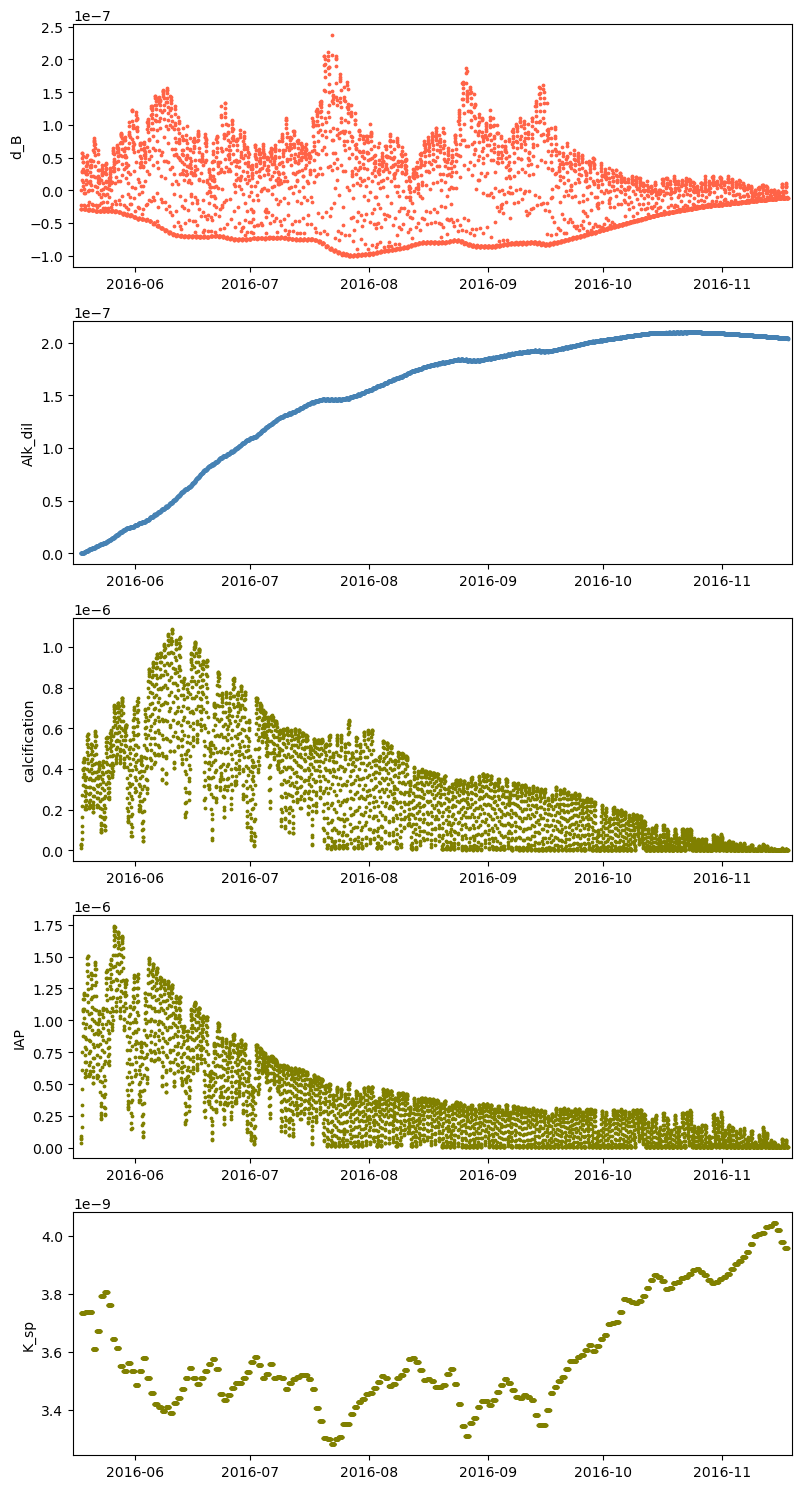

In [18]:
fig, axs = plt.subplots(5, figsize=(8, 15))

######## d_B ########
axs[0].scatter(df["date"], df["d_B"], s=3, color="tomato")
axs[0].set_ylabel('d_B')

######## Alk_dil ########
axs[1].scatter(df["date"], df["Alk_dil"], s=3, color="steelblue")
axs[1].set_ylabel('Alk_dil')

######## calcification ########
axs[2].scatter(df["date"], df["calcification"], s=3, color="olive")
axs[2].set_ylabel('calcification')
axs[3].scatter(df["date"], df["IAP"], s=3, color="olive")
axs[3].set_ylabel('IAP')
axs[4].scatter(df["date"], df["K_sp"], s=3, color="olive")
axs[4].set_ylabel('K_sp')


for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))


plt.tight_layout()
out = os.path.join(output_dir, f"Plots\\{file_name}_dAlk_components.png")
plt.savefig(out)

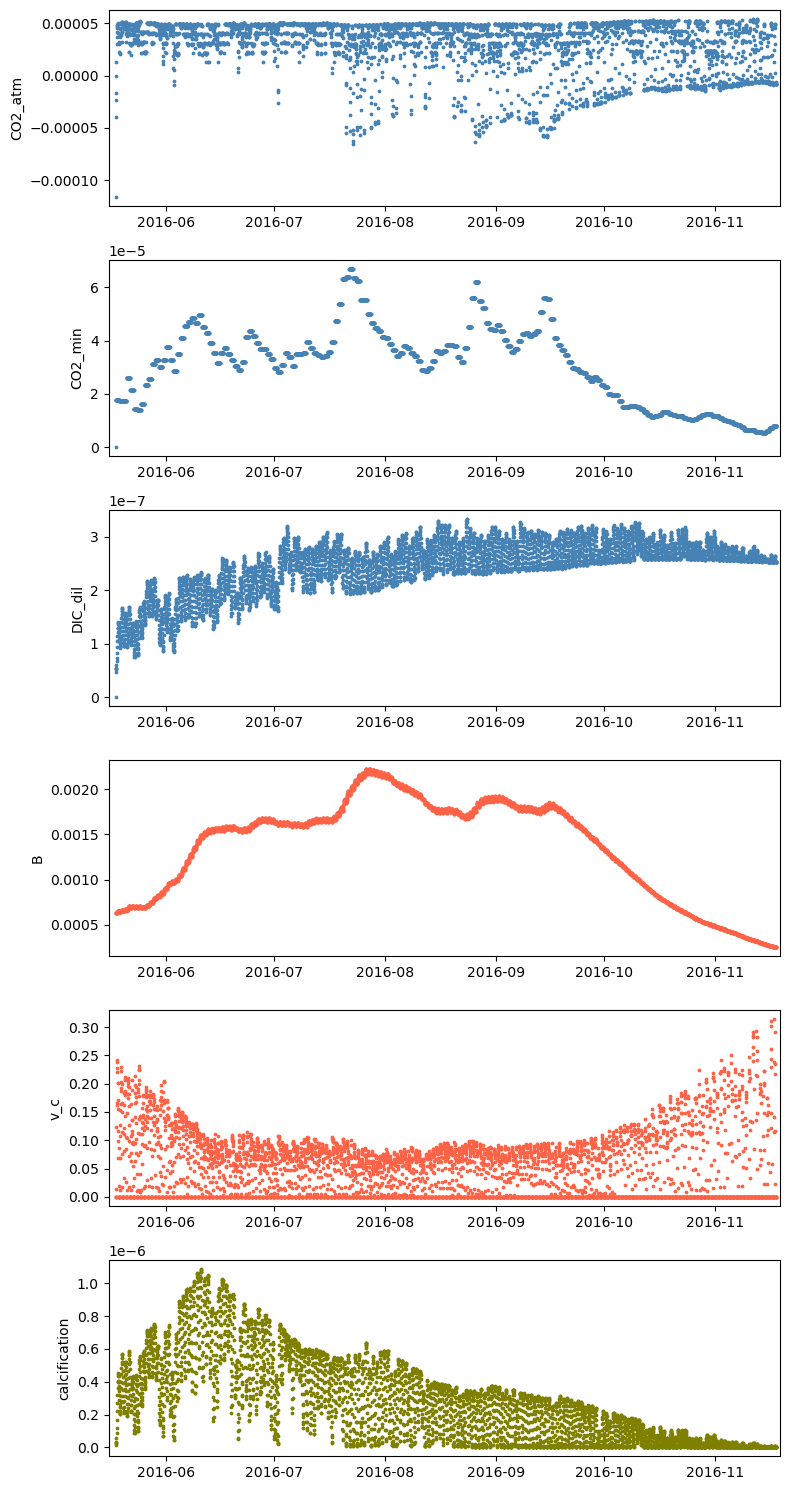

In [19]:
fig, axs = plt.subplots(6, figsize=(8, 15))



axs[0].scatter(df["date"], df["CO2_atm"], s=3, color="steelblue")
axs[0].set_ylabel('CO2_atm')

axs[1].scatter(df["date"], df["CO2_min"], s=3, color="steelblue")
axs[1].set_ylabel('CO2_min')

axs[2].scatter(df["date"], df["DIC_dil"], s=3, color="steelblue")
axs[2].set_ylabel('DIC_dil')

######## B ########
axs[3].scatter(df["date"], df["B"], s=3, color="tomato")
axs[3].set_ylabel('B')

######## v_c ########
axs[4].scatter(df["date"], df["v_c"], s=3, color="tomato")
axs[4].set_ylabel('v_c')


######## calcification ########
axs[5].scatter(df["date"], df["calcification"], s=3, color="olive")
axs[5].set_ylabel('calcification')
# axs[6].scatter(df["date"], df["IAP"], s=3, color="olive")
# axs[6].set_ylabel('IAP')
# axs[7].scatter(df["date"], df["K_sp"], s=3, color="olive")
# axs[7].set_ylabel('K_sp')


for ax in axs:
    ax.set_xlim(pd.to_datetime("2016-05-16"), pd.to_datetime("2016-11-19"))

plt.tight_layout()
out = os.path.join(output_dir, f"Plots\\{file_name}_dDIC_components.png")
plt.savefig(out)

### Old

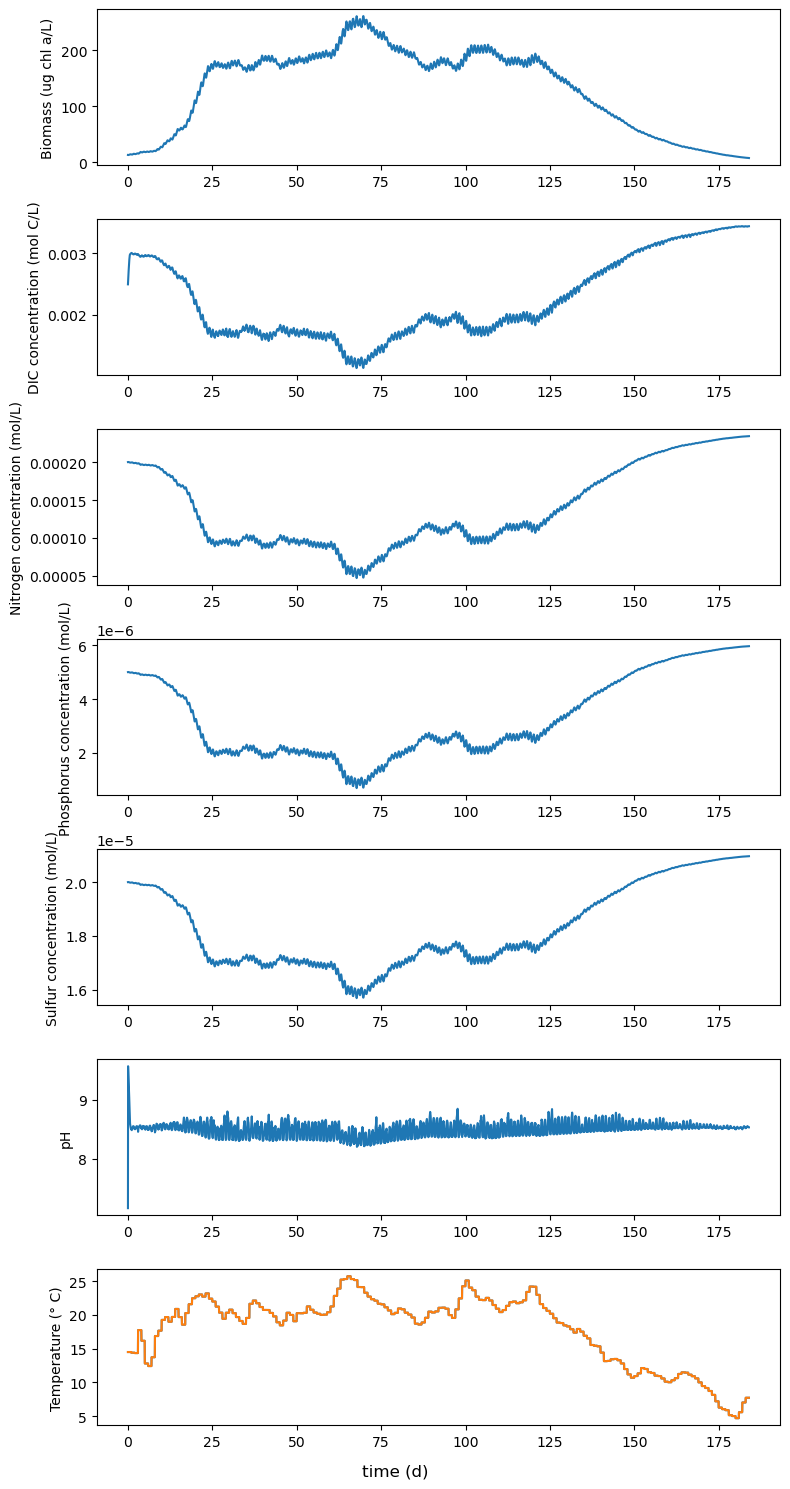

In [38]:
m = 400 * 24             # Get index for hourly data

x = (df.index[0:m])/24   # Only give hourly output
y1 = df["B"][0:m]
y2 = df["DIC"][0:m]
y3 = df["N"][0:m]
y4 = df["P_t"][0:m]
y5 = df["S"][0:m]
y6 = df["pH"][0:m]
y7 = df["t_c"][0:m]

fig, axs = plt.subplots(7, figsize=(8, 15))
# fig.suptitle('Vertically stacked subplots')
axs[0].plot(x, y1)
axs[1].plot(x, y2)
axs[2].plot(x, y3)
axs[3].plot(x, y4)
axs[4].plot(x, y5)
axs[5].plot(x, y6)
axs[6].plot(x, y7)

axs[0].set_ylabel('Biomass (ug chl a/L)')
axs[1].set_ylabel('DIC concentration (mol C/L)')
axs[2].set_ylabel('Nitrogen concentration (mol/L)')
axs[3].set_ylabel('Phosphorus concentration (mol/L)')
axs[4].set_ylabel('Sulfur concentration (mol/L)')
axs[5].set_ylabel('pH')
axs[6].set_ylabel('Temperature (\u00b0 C)')
fig.supxlabel('time (d)')
plt.tight_layout()

out = os.path.join(output_dir, "Plots\\Doortje_reproduced.png")
plt.savefig(out)

In [36]:
out = os.path.join(output_dir, "Plots\\Doortje_reproduced.png")
plt.savefig(out)

<Figure size 640x480 with 0 Axes>

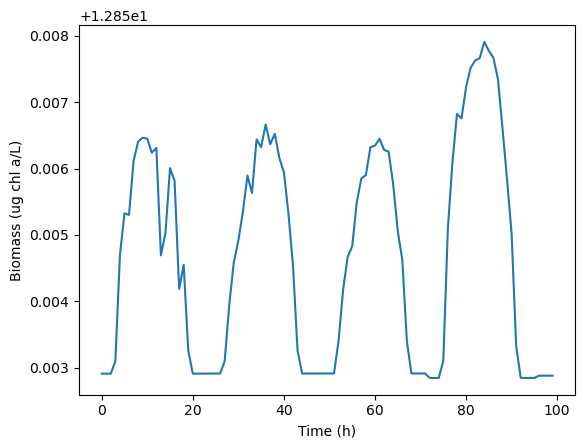

In [46]:
x = df.index[0:100]
y = df["B"][0:100]
plt.plot(x,y)
plt.xlabel("Time (h)")
plt.ylabel("Biomass (ug chl a/L")
plt.show()

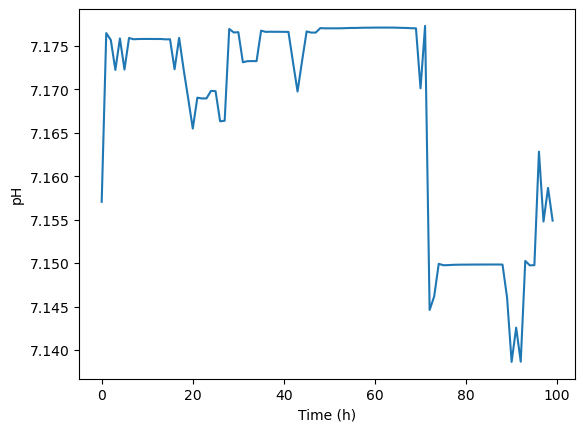

In [50]:
x = df.index[0:100]
y = df["pH"][0:100]
plt.plot(x,y)
plt.xlabel("Time (h)")
plt.ylabel("pH")
plt.show()

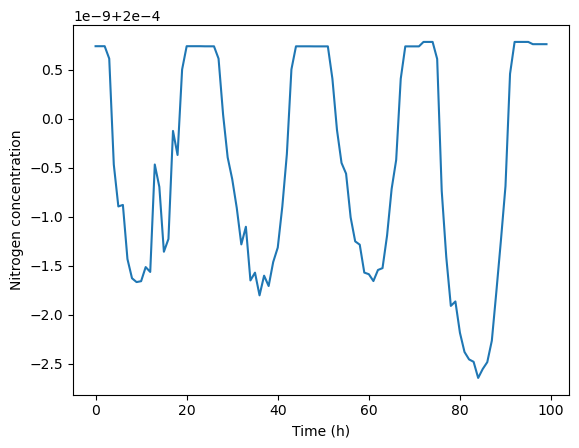

In [52]:
x = df.index[0:100]
y = df["N"][0:100]
plt.plot(x,y)
plt.xlabel("Time (h)")
plt.ylabel("Nitrogen concentration")
plt.show()

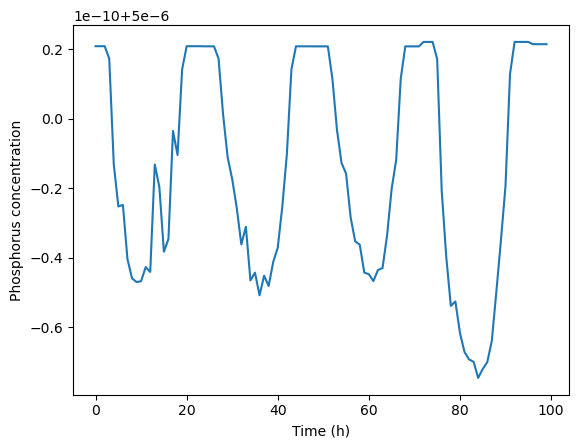

In [54]:
x = df.index[0:100]
y = df["P_t"][0:100]
plt.plot(x,y)
plt.xlabel("Time (h)")
plt.ylabel("Phosphorus concentration")
plt.show()